# Preparing Stocks

This notebook:

- loads the daily OHLCV data for all stock symbols,
- runs basic sanity checks on dates, missing values, and zeros,
- applies cleaning steps to the price columns (`Open`, `Close`, `Adj Close`, `Volume`).




# Import libraries And Useful Files

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np 
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
from src.utils.loading_data import *
from src.utils.data_inspection import *
from src.utils.data_inspection_viz import *
from src.utils.metadata_enrich import *
from src.utils.data_cleaning import *

# Loading Stocks

In [3]:

# Folder containing all stock CSVs
stocks_dir = Path("data/stocks")

# Dictionary to hold all loaded DataFrames
all_stocks = {}

# Loop over every CSV file in the folder
for csv_file in sorted(stocks_dir.glob("*.csv")):
    symbol = csv_file.stem  # e.g. AAPL.csv → AAPL
    df = load_symbol_from_dir(stocks_dir, symbol)
    all_stocks[symbol] = df
    print(f"Loaded {symbol}: {len(df)} rows")

print(f"\n✅ Loaded {len(all_stocks)} stock symbols total.")


Loaded A: 5124 rows
Loaded AA: 14663 rows
Loaded AACG: 261 rows
Loaded AAL: 3653 rows
Loaded AAMC: 1837 rows
Loaded AAME: 10098 rows
Loaded AAN: 9431 rows
Loaded AAOI: 1640 rows
Loaded AAON: 6873 rows
Loaded AAP: 4616 rows
Loaded AAPL: 9909 rows
Loaded AAT: 2319 rows
Loaded AAU: 3594 rows
Loaded AAWW: 3622 rows
Loaded AAXN: 4729 rows
Loaded AB: 8056 rows
Loaded ABB: 4776 rows
Loaded ABBV: 1825 rows
Loaded ABC: 6293 rows
Loaded ABCB: 6514 rows
Loaded ABEO: 9968 rows
Loaded ABEV: 5808 rows
Loaded ABG: 4540 rows
Loaded ABIO: 5699 rows
Loaded ABM: 10098 rows
Loaded ABMD: 8236 rows
Loaded ABR: 4024 rows
Loaded ABT: 10098 rows
Loaded ABTX: 1128 rows
Loaded ABUS: 3194 rows
Loaded AC: 3075 rows
Loaded ACA: 353 rows
Loaded ACAD: 3989 rows
Loaded ACAM: 227 rows
Loaded ACAMU: 280 rows
Loaded ACB: 5055 rows
Loaded ACBI: 1111 rows
Loaded ACC: 3935 rows
Loaded ACCO: 3681 rows
Loaded ACEL: 269 rows
Loaded ACER: 4020 rows
Loaded ACGL: 6180 rows
Loaded ACGLO: 658 rows
Loaded ACGLP: 886 rows
Loaded ACH:

## 3. Date sanity checks

In this section we verify the time axis of our stock data:

- Check that dates inside each symbol are strictly increasing.
- Show the global date range for all stocks.
- Find symbols that end too early (before a chosen cutoff date).
- Plot the distribution of start dates across all symbols.
- Add the column weekday for further use

These checks help us detect symbols with strange or truncated histories
before we start cleaning.


In [4]:
print("\n🔍 Checking if dates of stocks are in increasing order...")

for symbol, df in all_stocks.items():
    if dates_in_increasing_order(df):
        print(f"✅ {symbol}: dates are in increasing order.")
    else:
        print(f"⚠️ {symbol}: dates are NOT in increasing order!")



🔍 Checking if dates of stocks are in increasing order...
✅ A: dates are in increasing order.
✅ AA: dates are in increasing order.
✅ AACG: dates are in increasing order.
✅ AAL: dates are in increasing order.
✅ AAMC: dates are in increasing order.
✅ AAME: dates are in increasing order.
✅ AAN: dates are in increasing order.
✅ AAOI: dates are in increasing order.
✅ AAON: dates are in increasing order.
✅ AAP: dates are in increasing order.
✅ AAPL: dates are in increasing order.
✅ AAT: dates are in increasing order.
✅ AAU: dates are in increasing order.
✅ AAWW: dates are in increasing order.
✅ AAXN: dates are in increasing order.
✅ AB: dates are in increasing order.
✅ ABB: dates are in increasing order.
✅ ABBV: dates are in increasing order.
✅ ABC: dates are in increasing order.
✅ ABCB: dates are in increasing order.
✅ ABEO: dates are in increasing order.
✅ ABEV: dates are in increasing order.
✅ ABG: dates are in increasing order.
✅ ABIO: dates are in increasing order.
✅ ABM: dates are in i

In [5]:
show_date_ranges(all_stocks, "stocks")



 Date ranges for all stocks:

A: from 1999-11-18 → 2020-04-01
AA: from 1962-01-02 → 2020-04-01
AACG: from 2019-03-11 → 2020-04-01
AAL: from 2005-09-27 → 2020-04-01
AAMC: from 2012-12-13 → 2020-04-01
AAME: from 1980-03-17 → 2020-04-01
AAN: from 1982-11-04 → 2020-04-01
AAOI: from 2013-09-26 → 2020-04-01
AAON: from 1992-12-16 → 2020-04-01
AAP: from 2001-11-29 → 2020-04-01
AAPL: from 1980-12-12 → 2020-04-01
AAT: from 2011-01-13 → 2020-04-01
AAU: from 2005-12-20 → 2020-04-01
AAWW: from 2005-11-09 → 2020-04-01
AAXN: from 2001-06-08 → 2020-04-01
AB: from 1988-04-14 → 2020-04-01
ABB: from 2001-04-06 → 2020-04-01
ABBV: from 2013-01-02 → 2020-04-01
ABC: from 1995-04-04 → 2020-04-01
ABCB: from 1994-05-19 → 2020-04-01
ABEO: from 1980-09-19 → 2020-04-01
ABEV: from 1997-03-05 → 2020-04-01
ABG: from 2002-03-21 → 2020-04-01
ABIO: from 1997-08-08 → 2020-04-01
ABM: from 1980-03-17 → 2020-04-01
ABMD: from 1987-07-29 → 2020-04-01
ABR: from 2004-04-07 → 2020-04-01
ABT: from 1980-03-17 → 2020-04-01
ABTX: f

In [6]:
ends_before(all_stocks, "stocks", cutoff_date="2020-04-01")

 The following stocks end before 2020-04-01:
  - CARR#
  - LGF.B
  - SDPI
  - ZIONW


['CARR#', 'LGF.B', 'SDPI', 'ZIONW']

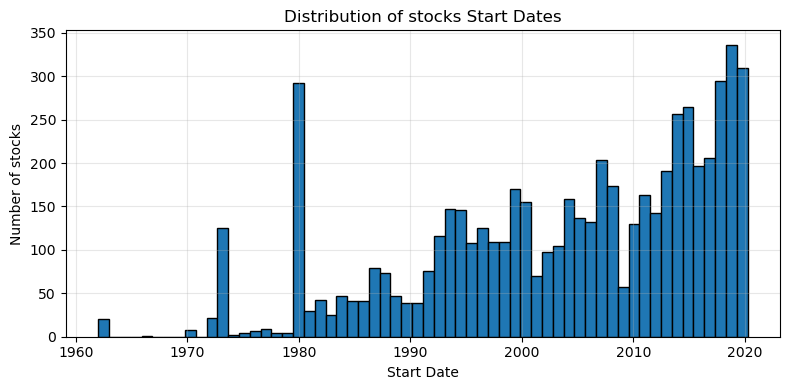

In [7]:
plot_start_date_distribution(all_stocks, "stocks")

In [8]:


def add_weekday_column(all_stocks, date_col="Date"):
    """
    Add a 'Weekday' column (0=Mon ... 4=Fri) right after the Date column.
    Modifies all_stocks in-place.
    """
    for symbol, df in all_stocks.items():

        # Ensure Date column is datetime
        df[date_col] = pd.to_datetime(df[date_col], errors="coerce")

        # Compute weekday (0=Mon ... 6=Sun, but your data only has 0-4)
        weekday = df[date_col].dt.weekday

        # Position where 'Date' is located
        idx = df.columns.get_loc(date_col)

        # Insert new column right after Date
        df.insert(idx + 1, "Weekday", weekday)
        
add_weekday_column(all_stocks)



## 4. Missing data analysis

Here we look at missing values in the stock time series.

We:

- compute, for each symbol, the fraction of missing values;
- compute overall missing rates for the whole dataset;
- plot how the number of missing entries evolves over time.

This gives an overview of the data quality and shows if certain periods
have more missing data than others.


In [9]:
missing_per_stock, missing_stocks = missing_rates_from_dict(all_stocks)

print(" Missing rates per stock:")
print(missing_per_stock.head())

print("\n Overall missing rates for stocks:")
print(missing_stocks)

 Missing rates per stock:
        Date  Weekday  Open  High  Low  Close  Adj Close  Volume  Symbol
Symbol                                                                  
A        0.0      0.0   0.0   0.0  0.0    0.0        0.0     0.0     0.0
AA       0.0      0.0   0.0   0.0  0.0    0.0        0.0     0.0     0.0
AACG     0.0      0.0   0.0   0.0  0.0    0.0        0.0     0.0     0.0
AAL      0.0      0.0   0.0   0.0  0.0    0.0        0.0     0.0     0.0
AAMC     0.0      0.0   0.0   0.0  0.0    0.0        0.0     0.0     0.0

 Overall missing rates for stocks:
           Total Missing Rate (%)
Date                     0.000000
Weekday                  0.000000
Open                     0.002682
High                     0.002682
Low                      0.002682
Close                    0.002682
Adj Close                0.002682
Volume                   0.002682
Symbol                   0.000000


/Users/chedliabdennebi/Desktop/ADA/projet/src/utils/data_inspection_viz.py:106: UserWarning: Glyph 128338 (\N{CLOCK FACE THREE OCLOCK}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/opt/anaconda3/lib/python3.13/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 128338 (\N{CLOCK FACE THREE OCLOCK}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


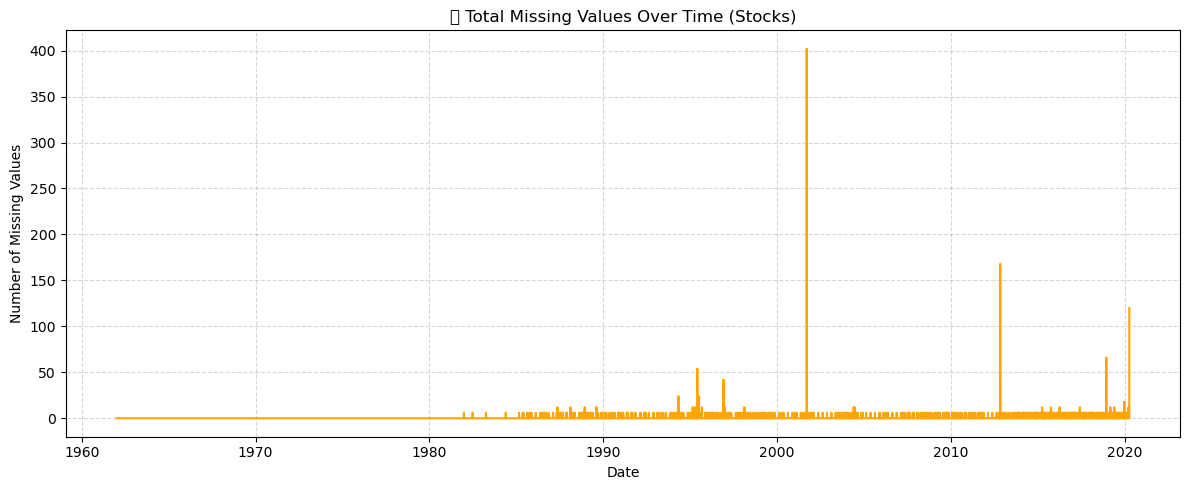

,Date,missing_count
0,1962-01-02,0
1,1962-01-03,0
2,1962-01-04,0
3,1962-01-05,0
4,1962-01-08,0
...,...,...
14712,2020-03-27,0
14713,2020-03-30,0
14714,2020-03-31,0
14715,2020-04-01,0


In [10]:
plot_missing_counts_over_time(all_stocks, label="Stocks")

In [11]:
def get_symbols_with_missing(all_stocks: dict, column: str):
    """
    Given a dict of DataFrames (key = symbol), return a list of symbols
    that have at least one missing value in the given column.
    """
    symbols = []

    for symbol, df in all_stocks.items():
        if column not in df.columns:
            raise ValueError(f"Column '{column}' not found in DataFrame for {symbol}")

        if df[column].isna().any():
            symbols.append(symbol)

    return sorted(symbols)


In [12]:
missing_open_symbols = get_symbols_with_missing(all_stocks, "Open")
missing_volume_symbols = get_symbols_with_missing(all_stocks, "Volume")
missing_high_symbols = get_symbols_with_missing(all_stocks, "High")
missing_low_symbols = get_symbols_with_missing(all_stocks, "Low")
missing_close_symbols = get_symbols_with_missing(all_stocks, "Close")
missing_adj_close_symbols = get_symbols_with_missing(all_stocks, "Adj Close")



In [13]:
print("Missing symbols for each column:\n")

print(f"Open:       {len(missing_open_symbols)} symbols")
print(missing_open_symbols[:20], "...\n" if len(missing_open_symbols) > 20 else "\n")

print(f"Volume:     {len(missing_volume_symbols)} symbols")
print(missing_volume_symbols[:20], "...\n" if len(missing_volume_symbols) > 20 else "\n")

print(f"High:       {len(missing_high_symbols)} symbols")
print(missing_high_symbols[:20], "...\n" if len(missing_high_symbols) > 20 else "\n")

print(f"Low:        {len(missing_low_symbols)} symbols")
print(missing_low_symbols[:20], "...\n" if len(missing_low_symbols) > 20 else "\n")

print(f"Close:      {len(missing_close_symbols)} symbols")
print(missing_close_symbols[:20], "...\n" if len(missing_close_symbols) > 20 else "\n")

print(f"Adj Close:  {len(missing_adj_close_symbols)} symbols")
print(missing_adj_close_symbols[:20], "...\n" if len(missing_adj_close_symbols) > 20 else "\n")


Missing symbols for each column:

Open:       256 symbols
['ADP', 'AEM', 'AFB', 'AGE', 'AGYS', 'AIG', 'AKR', 'ALB', 'ALOT', 'AMAT', 'AME', 'AMWD', 'AON', 'AOS', 'ASRVP', 'AT', 'AVT', 'AWF', 'AXP', 'BAC'] ...

Volume:     256 symbols
['ADP', 'AEM', 'AFB', 'AGE', 'AGYS', 'AIG', 'AKR', 'ALB', 'ALOT', 'AMAT', 'AME', 'AMWD', 'AON', 'AOS', 'ASRVP', 'AT', 'AVT', 'AWF', 'AXP', 'BAC'] ...

High:       256 symbols
['ADP', 'AEM', 'AFB', 'AGE', 'AGYS', 'AIG', 'AKR', 'ALB', 'ALOT', 'AMAT', 'AME', 'AMWD', 'AON', 'AOS', 'ASRVP', 'AT', 'AVT', 'AWF', 'AXP', 'BAC'] ...

Low:        256 symbols
['ADP', 'AEM', 'AFB', 'AGE', 'AGYS', 'AIG', 'AKR', 'ALB', 'ALOT', 'AMAT', 'AME', 'AMWD', 'AON', 'AOS', 'ASRVP', 'AT', 'AVT', 'AWF', 'AXP', 'BAC'] ...

Close:      256 symbols
['ADP', 'AEM', 'AFB', 'AGE', 'AGYS', 'AIG', 'AKR', 'ALB', 'ALOT', 'AMAT', 'AME', 'AMWD', 'AON', 'AOS', 'ASRVP', 'AT', 'AVT', 'AWF', 'AXP', 'BAC'] ...

Adj Close:  256 symbols
['ADP', 'AEM', 'AFB', 'AGE', 'AGYS', 'AIG', 'AKR', 'ALB', 'ALOT', '

In [14]:
# Put all lists into a dictionary for convenience
missing_dict = {
    "Open": missing_open_symbols,
    "Volume": missing_volume_symbols,
    "High": missing_high_symbols,
    "Low": missing_low_symbols,
    "Close": missing_close_symbols,
    "Adj Close": missing_adj_close_symbols
}

# Convert lists to sets for easy comparison
missing_sets = {col: set(syms) for col, syms in missing_dict.items()}

# Take the first set as reference
first_col = list(missing_sets.keys())[0]
reference_set = missing_sets[first_col]

# Check if all sets match the reference
all_same = all(missing_sets[col] == reference_set for col in missing_sets)

print("---------------------------------------------------")
if all_same:
    print("✅ All columns have missing values in EXACTLY the same symbols.")
else:
    print("❌ Columns do NOT have missing values in the same symbols.\n")

    # Show which ones differ
    print("Differences:")
    for col, s in missing_sets.items():
        if s != reference_set:
            print(f"- {col} differs from {first_col}")


---------------------------------------------------
✅ All columns have missing values in EXACTLY the same symbols.


# 5. Cleaning Missing Values

Since only 4.35% of the stocks' symbols have missing values, we'll just remove them

In [15]:
def remove_missing_symbols(all_stocks: dict, symbols_to_remove: list):
    """
    Removes the given symbols from the all_stocks dict (in-place).

    Parameters
    ----------
    all_stocks : dict
        Dictionary where keys = stock symbols and values = DataFrames.
    symbols_to_remove : list
        List of symbols to delete from all_stocks.
    """
    for sym in symbols_to_remove:
        if sym in all_stocks:
            del all_stocks[sym]

symbols_to_remove = missing_open_symbols  # since they are all the same
remove_missing_symbols(all_stocks, symbols_to_remove)
print("Remaining symbols:", len(all_stocks))
print("Removed symbols:", len(symbols_to_remove))


Remaining symbols: 5628
Removed symbols: 256


In [16]:
missing_per_stock, missing_stocks = missing_rates_from_dict(all_stocks)

print(" Missing rates per stock:")
print(missing_per_stock.head())

print("\n Overall missing rates for stocks:")
print(missing_stocks)

 Missing rates per stock:
        Date  Weekday  Open  High  Low  Close  Adj Close  Volume  Symbol
Symbol                                                                  
A        0.0      0.0   0.0   0.0  0.0    0.0        0.0     0.0     0.0
AA       0.0      0.0   0.0   0.0  0.0    0.0        0.0     0.0     0.0
AACG     0.0      0.0   0.0   0.0  0.0    0.0        0.0     0.0     0.0
AAL      0.0      0.0   0.0   0.0  0.0    0.0        0.0     0.0     0.0
AAMC     0.0      0.0   0.0   0.0  0.0    0.0        0.0     0.0     0.0

 Overall missing rates for stocks:
           Total Missing Rate (%)
Date                          0.0
Weekday                       0.0
Open                          0.0
High                          0.0
Low                           0.0
Close                         0.0
Adj Close                     0.0
Volume                        0.0
Symbol                        0.0


## 5. Zero-value analysis

Zeros in price or volume columns can be problematic: they may represent bad data 

In this section we:

- measure how often each symbol has zero values;
- compute overall zero rates;
- plot the number of zeros over time for several columns:
  - `Open`
  - `Volume`
  - `Adj Close`
  - `Close`

This tells us whether zeros are rare anomalies or a systematic issue that needs cleaning.


In [17]:
zero_per_symbol_stocks, zero_overall_stocks = zero_rates_from_dict(all_stocks)
print(" Zero value rates per symbol (STOCKS):")


print("\n Overall zero value rates (STOCKS):")
print(zero_overall_stocks)


 Zero value rates per symbol (STOCKS):

 Overall zero value rates (STOCKS):
           Total Zero Rate (%)
Weekday              18.850887
Open                  4.504569
High                  0.000081
Low                   0.000081
Close                 0.000076
Adj Close             0.000076
Volume                5.790265


/Users/chedliabdennebi/Desktop/ADA/projet/src/utils/data_inspection_viz.py:175: UserWarning: Glyph 128338 (\N{CLOCK FACE THREE OCLOCK}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/opt/anaconda3/lib/python3.13/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 128338 (\N{CLOCK FACE THREE OCLOCK}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


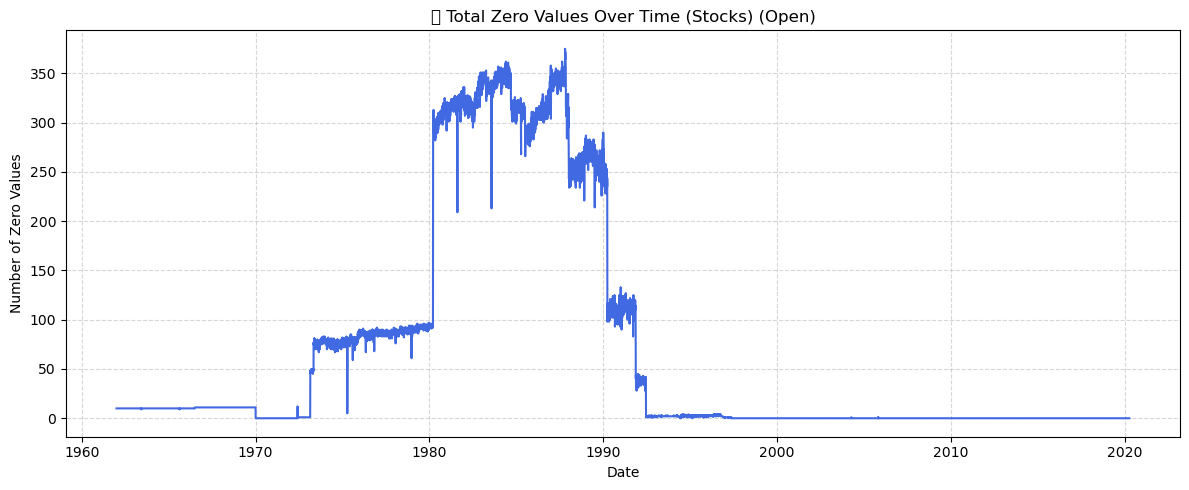

,Date,zero_count
0,1962-01-02,10
1,1962-01-03,10
2,1962-01-04,10
3,1962-01-05,10
4,1962-01-08,10
...,...,...
14658,2020-03-26,0
14659,2020-03-27,0
14660,2020-03-30,0
14661,2020-03-31,0


In [18]:
plot_zero_counts_over_time(all_stocks, label="Stocks",column="Open")


/Users/chedliabdennebi/Desktop/ADA/projet/src/utils/data_inspection_viz.py:175: UserWarning: Glyph 128338 (\N{CLOCK FACE THREE OCLOCK}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/opt/anaconda3/lib/python3.13/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 128338 (\N{CLOCK FACE THREE OCLOCK}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


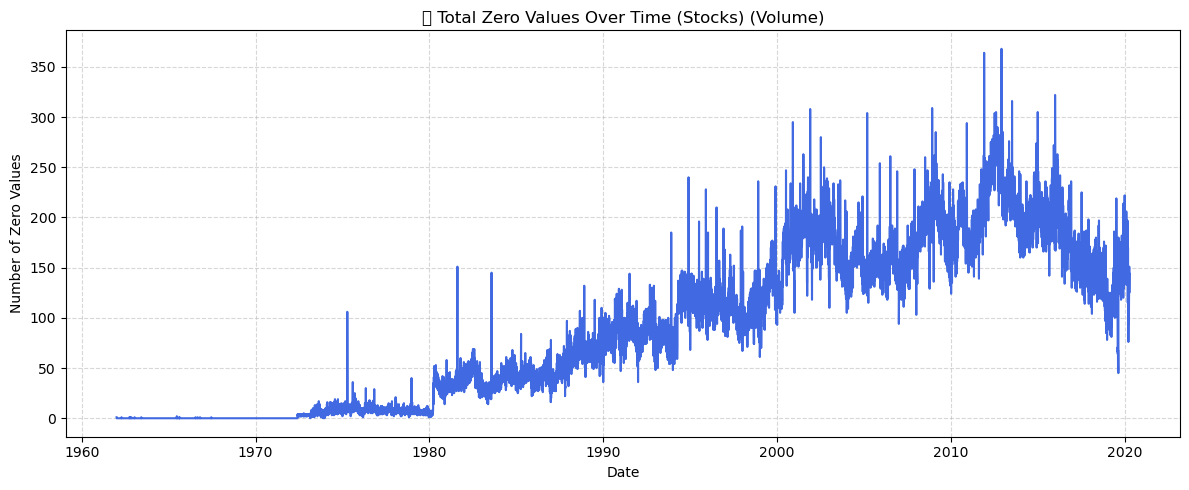

,Date,zero_count
0,1962-01-02,1
1,1962-01-03,0
2,1962-01-04,0
3,1962-01-05,0
4,1962-01-08,0
...,...,...
14658,2020-03-26,132
14659,2020-03-27,124
14660,2020-03-30,151
14661,2020-03-31,125


In [19]:
plot_zero_counts_over_time(all_stocks, label="Stocks",column="Volume")

/Users/chedliabdennebi/Desktop/ADA/projet/src/utils/data_inspection_viz.py:175: UserWarning: Glyph 128338 (\N{CLOCK FACE THREE OCLOCK}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/opt/anaconda3/lib/python3.13/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 128338 (\N{CLOCK FACE THREE OCLOCK}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


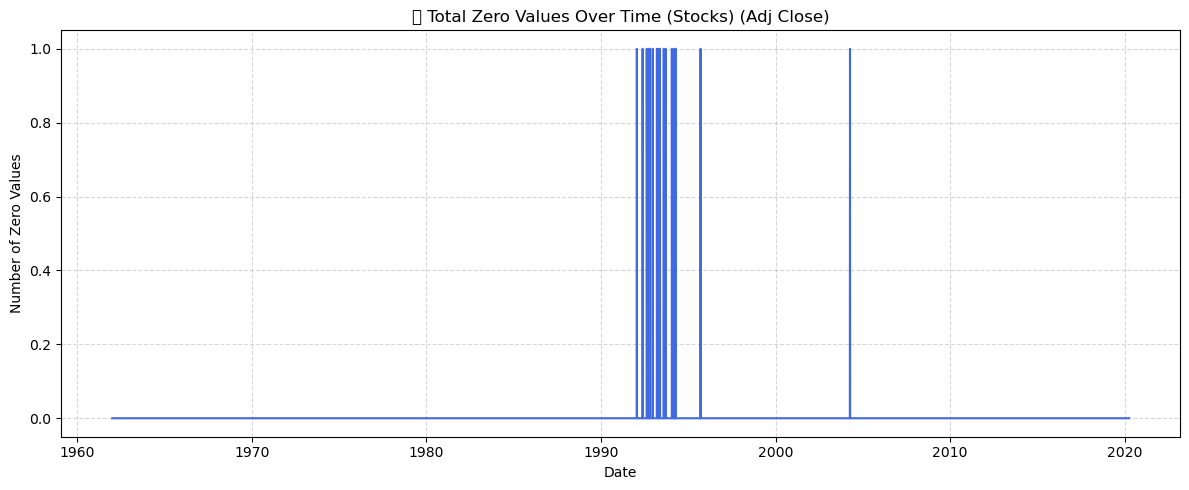

,Date,zero_count
0,1962-01-02,0
1,1962-01-03,0
2,1962-01-04,0
3,1962-01-05,0
4,1962-01-08,0
...,...,...
14658,2020-03-26,0
14659,2020-03-27,0
14660,2020-03-30,0
14661,2020-03-31,0


In [20]:
plot_zero_counts_over_time(all_stocks, label="Stocks",column="Adj Close")

/Users/chedliabdennebi/Desktop/ADA/projet/src/utils/data_inspection_viz.py:175: UserWarning: Glyph 128338 (\N{CLOCK FACE THREE OCLOCK}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/opt/anaconda3/lib/python3.13/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 128338 (\N{CLOCK FACE THREE OCLOCK}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


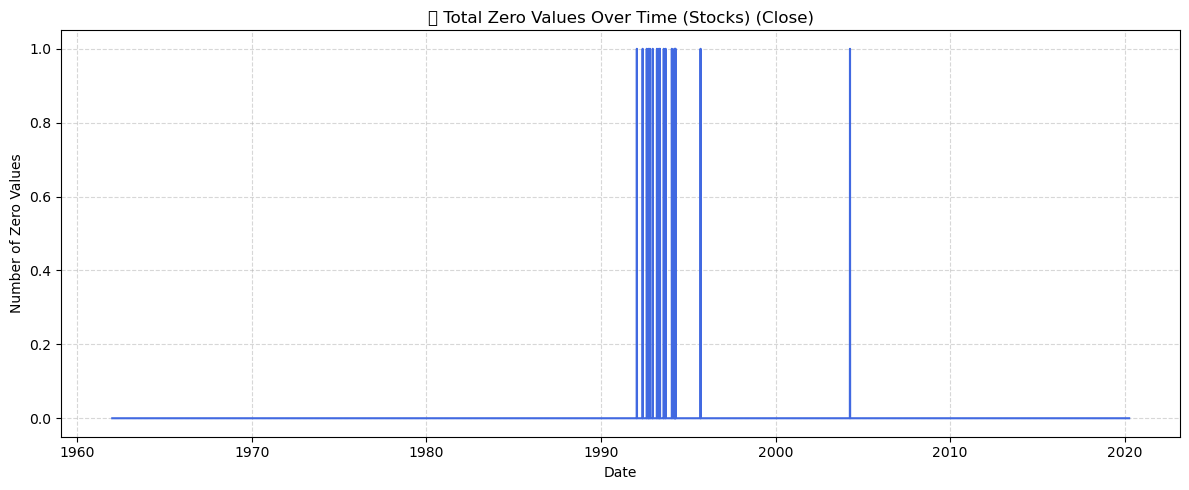

,Date,zero_count
0,1962-01-02,0
1,1962-01-03,0
2,1962-01-04,0
3,1962-01-05,0
4,1962-01-08,0
...,...,...
14658,2020-03-26,0
14659,2020-03-27,0
14660,2020-03-30,0
14661,2020-03-31,0


In [21]:
plot_zero_counts_over_time(all_stocks, label="Stocks",column="Close")

/Users/chedliabdennebi/Desktop/ADA/projet/src/utils/data_inspection_viz.py:175: UserWarning: Glyph 128338 (\N{CLOCK FACE THREE OCLOCK}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/opt/anaconda3/lib/python3.13/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 128338 (\N{CLOCK FACE THREE OCLOCK}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


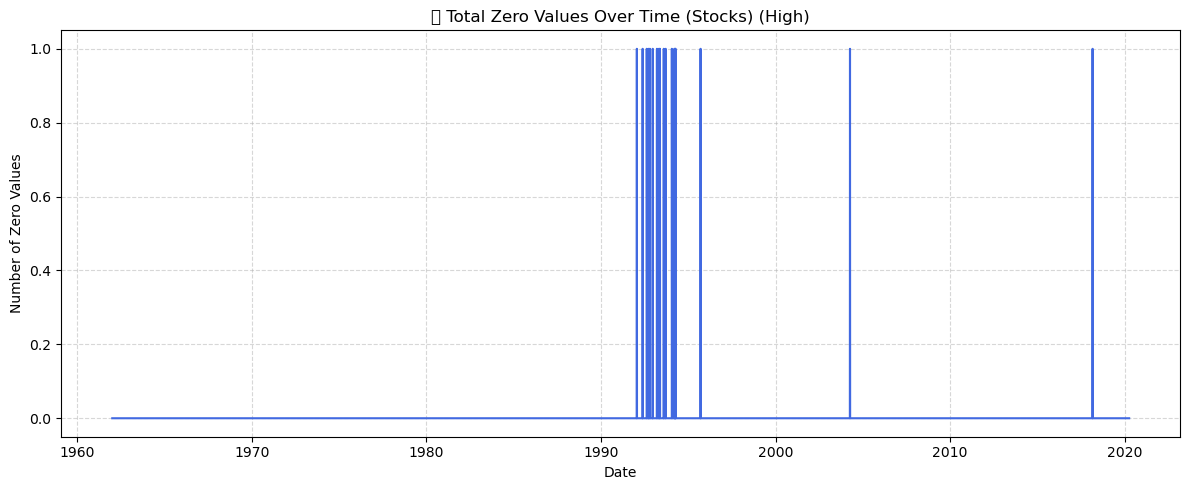

,Date,zero_count
0,1962-01-02,0
1,1962-01-03,0
2,1962-01-04,0
3,1962-01-05,0
4,1962-01-08,0
...,...,...
14658,2020-03-26,0
14659,2020-03-27,0
14660,2020-03-30,0
14661,2020-03-31,0


In [22]:
plot_zero_counts_over_time(all_stocks, label="Stocks",column="High")

/Users/chedliabdennebi/Desktop/ADA/projet/src/utils/data_inspection_viz.py:175: UserWarning: Glyph 128338 (\N{CLOCK FACE THREE OCLOCK}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/opt/anaconda3/lib/python3.13/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 128338 (\N{CLOCK FACE THREE OCLOCK}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


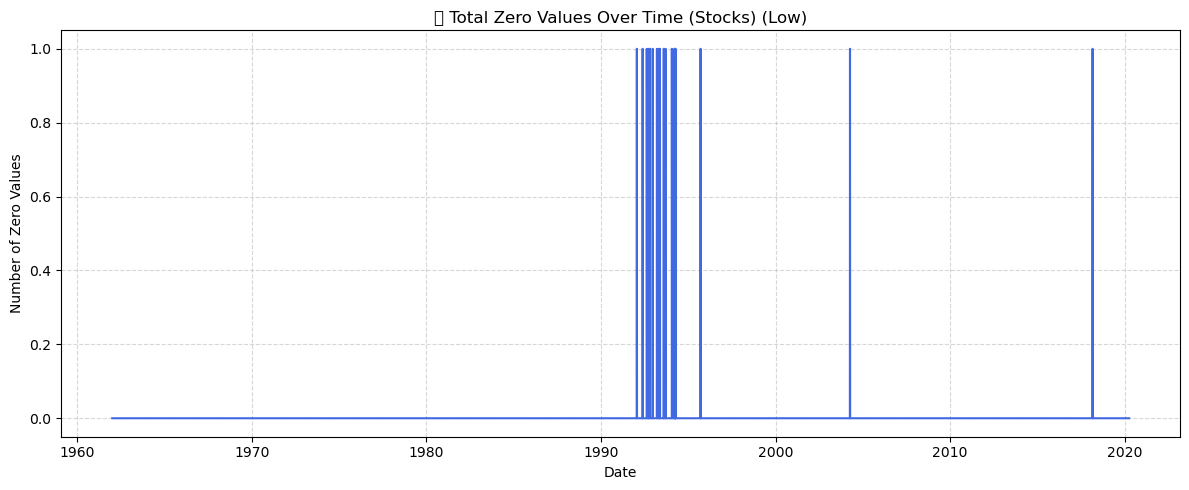

,Date,zero_count
0,1962-01-02,0
1,1962-01-03,0
2,1962-01-04,0
3,1962-01-05,0
4,1962-01-08,0
...,...,...
14658,2020-03-26,0
14659,2020-03-27,0
14660,2020-03-30,0
14661,2020-03-31,0


In [23]:
plot_zero_counts_over_time(all_stocks, label="Stocks",column="Low")

In [24]:
zero_symbols_high = get_symbols_with_zeros(all_stocks, "High")
print(zero_symbols_high)
zero_symbols_low = get_symbols_with_zeros(all_stocks, "Low")
print(zero_symbols_low)

['APEX', 'ASYS', 'AXDX', 'HWKN', 'KERN', 'MAYS', 'NEOG', 'NRIM', 'PMD', 'PNRG', 'RMCF', 'SEED', 'STRL']
['APEX', 'ASYS', 'AXDX', 'HWKN', 'KERN', 'MAYS', 'NEOG', 'NRIM', 'PMD', 'PNRG', 'RMCF', 'SEED', 'STRL']


In [25]:
zero_symbols_vol = get_symbols_with_zeros(all_stocks, "Volume")
print(zero_symbols_vol)

['AA', 'AAMC', 'AAME', 'AAN', 'AAON', 'AAWW', 'ABCB', 'ABEO', 'ABEV', 'ABIO', 'ABM', 'ABMD', 'ABUS', 'AC', 'ACAD', 'ACAM', 'ACAMU', 'ACB', 'ACEL', 'ACER', 'ACGL', 'ACH', 'ACHC', 'ACHV', 'ACNB', 'ACOR', 'ACRS', 'ACRX', 'ACST', 'ACTT', 'ACTTU', 'ACU', 'ACV', 'ACY', 'ADC', 'ADES', 'ADMA', 'ADMP', 'ADNT', 'ADUS', 'ADXN', 'ADXS', 'AE', 'AEF', 'AEG', 'AEGN', 'AEHR', 'AEMD', 'AESE', 'AEY', 'AEYE', 'AEZS', 'AFC', 'AFG', 'AFH', 'AFI', 'AFL', 'AG', 'AGBA', 'AGBAU', 'AGCO', 'AGFS', 'AGI', 'AGM-A', 'AGM', 'AGMH', 'AGNCN', 'AGRX', 'AGX', 'AHCO', 'AHPI', 'AIC', 'AIH', 'AIM', 'AIN', 'AINC', 'AIO', 'AIR', 'AIRI', 'AIRT', 'AIRTP', 'AIT', 'AIW', 'AIZP', 'AJG', 'AJXA', 'AKCA', 'AKER', 'AKRX', 'AKTS', 'AKTX', 'ALAC', 'ALACR', 'ALACU', 'ALBO', 'ALC', 'ALCO', 'ALDX', 'ALE', 'ALEX', 'ALG', 'ALGR', 'ALGRU', 'ALJJ', 'ALKS', 'ALLT', 'ALLY', 'ALO', 'ALRS', 'ALSK', 'ALT', 'ALTG', 'ALTR', 'ALUS', 'ALX', 'ALXN', 'ALYA', 'AMAG', 'AMBO', 'AMCI', 'AMCIU', 'AMCR', 'AMD', 'AMED', 'AMEH', 'AMGN', 'AMHC', 'AMHCU', 'AMK', 

In [26]:
zero_symbols_close_adj = get_symbols_with_zeros(all_stocks, "Adj Close")
print(zero_symbols_close_adj)
zero_symbols_close = get_symbols_with_zeros(all_stocks, "Close")
print(zero_symbols_close)
print (zero_symbols_close_adj == zero_symbols_close)




['APEX', 'ASYS', 'AXDX', 'HWKN', 'MAYS', 'NEOG', 'NRIM', 'PMD', 'PNRG', 'RMCF', 'SEED', 'STRL']
['APEX', 'ASYS', 'AXDX', 'HWKN', 'MAYS', 'NEOG', 'NRIM', 'PMD', 'PNRG', 'RMCF', 'SEED', 'STRL']
True


In [27]:
print(type(zero_symbols_close_adj))
print(zero_symbols_close_adj)


<class 'list'>
['APEX', 'ASYS', 'AXDX', 'HWKN', 'MAYS', 'NEOG', 'NRIM', 'PMD', 'PNRG', 'RMCF', 'SEED', 'STRL']


## 6. Cleaning Zero Value Columns (`Open`, `Close`, `Adj Close`, `Volume` )

Using the information from the previous diagnostics, we now clean the price data:

1. Identify symbols where `Adj Close`, `Close`, `High`, `Low`  contain zeros.
2. Remove the worst symbols if they are too corrupted.
3. Fill remaining `Adj Close` gaps (NaNs) using a suitable rule.
4. Fix `Open` and `Close` when they are zero or inconsistent by using
   the `Adj Close` value from the previous or current day.
5. 
6. 


In [34]:
def remove_symbols_zero(all_stocks: dict, symbols_to_remove: list):
    """
    Remove a list of symbols from the all_stocks dict (in-place).

    Parameters
    ----------
    all_stocks : dict
        Dict containing symbol → DataFrame.
    symbols_to_remove : list
        List of symbols to delete.
    """
    for sym in symbols_to_remove:
        if sym in all_stocks:
            del all_stocks[sym]


remove_symbols_zero(all_stocks, zero_symbols_close_adj)


TypeError: argument of type 'NoneType' is not iterable

In [29]:

all_stocks = remove_symbols_zero(all_stocks, zero_symbols_high)

In [33]:
fix_open_with_prev_adjclose(all_stocks)

AttributeError: 'NoneType' object has no attribute 'items'

In [32]:
fix_close_with_adjclose(all_stocks)

AttributeError: 'NoneType' object has no attribute 'items'

In [30]:
zero_per_symbol_stocks, zero_overall_stocks = zero_rates_from_dict(all_stocks)
print(" Zero value rates per symbol (STOCKS):")


print("\n Overall zero value rates (STOCKS):")
print(zero_overall_stocks)
